# Data Description of YouNiverse

In [1]:
import sys
import os
# This finds the directory *above* 'tests', which is your project root.
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))

if project_root not in sys.path:
    sys.path.insert(0, project_root)


# Imports
from scipy.stats import mannwhitneyu

from src.data.loader import load_all_raw_datasets, iterate_parquet_stream
from src.data.preprocessing import apply_data_processing
from src.data.quality_check import check_data_quality_on_datasets
from src.models.log_log_efficiency_model import linear_log_log_model
from src.utils.general_utils import weighted_percentiles
from config import (
    DATASET_CHANNELS,
    DATASET_TIMESERIES,
    DATASET_VIDEO_LIGHT
)
from src.utils.plots import *

# Style
sns.set_style("whitegrid")
sns.set_palette("husl")
seed = 6 # for reproducing the results

%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [2]:
channel_df = pd.read_parquet(DATASET_CHANNELS)
channel_df.columns

Index(['category_cc', 'join_date', 'channel', 'name_cc', 'subscribers_cc',
       'videos_cc', 'subscriber_rank_sb', 'weights', 'channel_age_days',
       'videos_per_day', 'avg_engagement_efficiency', 'total_views',
       'total_duration', 'total_like_count', 'total_dislike_count',
       'total_num_comms', 'avg_video_like_ratio', 'video_count_processed'],
      dtype='object')

In [3]:
outperformers = pd.read_parquet(
    r"C:\Users\Jon\Desktop\ADA Project2\ada-2025-project-in5ight\data\cached_results\channels_outperformers.parquet"
)


In [4]:
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)

In [5]:
channel_time_df = outperformers.merge(timeseries_df, how="inner", on="channel")
channel_time_df.head()

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,activity,week_start,efficiency_4week,efficiency_4week_filled,posting_pace_4w,posting_consistency_4w,posting_pace_8w,posting_consistency_8w,posting_pace_12w,posting_consistency_12w
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,...,14,2016-10-11,0.046551,0.046551,0.0,0.0000,0.0,0.000000,0.0,0.000000
1,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,...,14,2016-10-18,0.044049,0.044049,0.0,1.0000,0.0,1.000000,0.0,1.000000
2,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,...,15,2016-10-25,0.045417,0.045417,0.0,0.0000,0.0,0.000000,0.0,0.000000
3,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,...,15,2016-11-01,0.047641,0.047641,6.0,0.0000,6.0,0.000000,6.0,0.000000
4,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,...,14,2016-11-08,0.052416,0.052416,7.0,0.3267,6.0,0.081441,6.0,0.081441


In [19]:
channel_time_df.columns

Index(['category_cc', 'join_date', 'channel', 'name_cc', 'subscribers_cc',
       'videos_cc', 'subscriber_rank_sb', 'weights', 'channel_age_days',
       'videos_per_day', 'avg_engagement_efficiency', 'total_views',
       'total_duration', 'total_like_count', 'total_dislike_count',
       'total_num_comms', 'avg_video_like_ratio', 'video_count_processed',
       'is_outperformer', 'category', 'datetime', 'views', 'delta_views',
       'subs', 'delta_subs', 'videos', 'delta_videos', 'activity',
       'week_start', 'efficiency_4week', 'efficiency_4week_filled',
       'posting_pace_4w', 'posting_consistency_4w', 'posting_pace_8w',
       'posting_consistency_8w', 'posting_pace_12w',
       'posting_consistency_12w'],
      dtype='object')

In [6]:
small_mid_sized_channels_df = channel_df[channel_df["subscribers_cc"] < 100_000].copy()

In [56]:
# Cell 1: Run the model on your static data and extract coefficients

# 1. Run the model on the static channel data (as you described)
# This identifies the global relationship: log(Efficiency) = a + b * log(Subscribers)
channels_model_df = linear_log_log_model(
    df=small_mid_sized_channels_df, # Your static dataset
    x_col="subscribers_cc",
    y_col="avg_engagement_efficiency",
    weight_col="weights",
    log_base=10,
    verbose=True,
)

# 2. Extract the slope (b) and intercept (a) from the custom attributes
model_params = channels_model_df.attrs["model"]
intercept_a = model_params["a"]
slope_b = model_params["b"]

print(f"Global Baseline Established: Intercept (a) = {intercept_a:.4f}, Slope (b) = {slope_b:.4f}")
print("Concept: As channel size grows, expected efficiency scales by a factor of", round(slope_b, 4))

log–log model fitted: log(y) = -0.9058 + -0.1419 * log(x)
Global Baseline Established: Intercept (a) = -0.9058, Slope (b) = -0.1419
Concept: As channel size grows, expected efficiency scales by a factor of -0.1419


In [45]:
# Cell 2: Data Prep (Creating the "Bridge" Data)

# 1. Select the specific outperformers
top_channel_ids = (
    outperformers
    .sort_values("avg_engagement_efficiency", ascending=False)
    .head(5)["channel"]
    .unique()
)

# 2. Filter the time-series dataframe
df_viz = channel_time_df[channel_time_df['channel'].isin(top_channel_ids)].copy()
df_viz['week_start'] = pd.to_datetime(df_viz['week_start'])
df_viz = df_viz.sort_values(['channel', 'week_start'])

# 3. Calculate Baseline
df_viz = df_viz.dropna(subset=['subs']) 
df_viz['log_subs_dynamic'] = np.log10(df_viz['subs'])
df_viz['log_expected_efficiency'] = intercept_a + (slope_b * df_viz['log_subs_dynamic'])
df_viz['expected_baseline'] = 10 ** df_viz['log_expected_efficiency']

# 4. Prepare the "Gap" Logic
# Ensure 0s are NaNs so they count as gaps
df_viz.loc[df_viz['efficiency_4week'] == 0, 'efficiency_4week'] = np.nan

# Create a NEW column that fills the gaps (for the dashed line)
# We use interpolate to draw a straight line between the existing points
df_viz['efficiency_bridged'] = df_viz.groupby('channel')['efficiency_4week'].transform(
    lambda x: x.interpolate(method='linear', limit_direction='both')
)

print("Data prepared: 'efficiency_4week' has gaps, 'efficiency_bridged' is full.")

Data prepared: 'efficiency_4week' has gaps, 'efficiency_bridged' is full.


In [ ]:
df_viz.

,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,...,posting_pace_4w,posting_consistency_4w,posting_pace_8w,posting_consistency_8w,posting_pace_12w,posting_consistency_12w,log_subs_dynamic,log_expected_efficiency,expected_baseline,efficiency_bridged
14806091,People & Blogs,2013-08-15,UCDNlTovDJmWXXuu0Vr3dSkA,thestarsiens,19300,72,615445.0,9.947,2264.0,0.031802,...,0.0,0.0,0.0,0.0,0.0,0.0,4.290788,-1.514499,0.030584,NaN
14806092,People & Blogs,2013-08-15,UCDNlTovDJmWXXuu0Vr3dSkA,thestarsiens,19300,72,615445.0,9.947,2264.0,0.031802,...,0.0,1.0,0.0,1.0,0.0,1.0,4.290266,-1.514425,0.030590,NaN
14806093,People & Blogs,2013-08-15,UCDNlTovDJmWXXuu0Vr3dSkA,thestarsiens,19300,72,615445.0,9.947,2264.0,0.031802,...,0.0,1.0,0.0,1.0,0.0,1.0,4.289774,-1.514355,0.030595,NaN
14806094,People & Blogs,2013-08-15,UCDNlTovDJmWXXuu0Vr3dSkA,thestarsiens,19300,72,615445.0,9.947,2264.0,0.031802,...,0.0,1.0,0.0,1.0,0.0,1.0,4.289404,-1.514302,0.030598,NaN
14806095,People & Blogs,2013-08-15,UCDNlTovDJmWXXuu0Vr3dSkA,thestarsiens,19300,72,615445.0,9.947,2264.0,0.031802,...,0.0,1.0,0.0,1.0,0.0,1.0,4.289082,-1.514257,0.030602,NaN


In [23]:
import plotly.graph_objects as go

# Cell 3: The "Solid-Dash-Solid" Visualization

fig = go.Figure()

unique_channels = df_viz['channel'].unique()
id_to_name = df_viz.groupby('channel')['name_cc'].first().to_dict()

first_channel = True

for ch_id in unique_channels:
    ch_data = df_viz[df_viz['channel'] == ch_id]
    
    is_visible = first_channel
    
    # TRACE 1: The "Bridge" (Dashed Line)
    # This runs underneath. It connects the gaps with a dashed style.
    fig.add_trace(go.Scatter(
        x=ch_data['week_start'],
        y=ch_data['efficiency_bridged'],
        mode='lines',
        name='Projected Path', # Optional to show in legend
        line=dict(color='#00CC96', width=2, dash='dash'), # Green Dashed
        opacity=0.6, # Slightly lighter to show it's inferred
        visible=is_visible,
        showlegend=False, # Hide from legend to keep it clean
        hoverinfo='skip'  # Don't show hover data for the fake points
    ))

    # TRACE 2: The "Real Data" (Solid Line)
    # This sits ON TOP. It has gaps where data is missing.
    fig.add_trace(go.Scatter(
        x=ch_data['week_start'],
        y=ch_data['efficiency_4week'],
        mode='lines',
        name='Actual Efficiency',
        line=dict(color='#00CC96', width=3), # Solid Green
        visible=is_visible,
    ))

    # TRACE 3: The Baseline
    fig.add_trace(go.Scatter(
        x=ch_data['week_start'],
        y=ch_data['expected_baseline'],
        mode='lines',
        name='Expected Baseline',
        line=dict(color='#EF553B', width=2, dash='dot'),
        visible=is_visible,
    ))
    
    first_channel = False

# --- Dropdown Logic ---
buttons = []
num_channels = len(unique_channels)

for i, ch_id in enumerate(unique_channels):
    # We now have 3 traces per channel.
    visibility = [False] * (num_channels * 3)
    
    # Turn on the triplet for this channel
    visibility[3*i] = True      # Bridge
    visibility[3*i + 1] = True  # Real
    visibility[3*i + 2] = True  # Baseline
    
    label_name = id_to_name.get(ch_id, ch_id)
    
    buttons.append(dict(
        label=label_name,
        method="update",
        args=[{"visible": visibility},
              {"title": f"Outperformer Journey: {label_name}"}]
    ))

fig.update_layout(
    title=f"Outperformer Journey: {id_to_name.get(unique_channels[0], 'Select a Channel')}",
    xaxis_title="Timeline",
    yaxis_title="Engagement Efficiency",
    updatemenus=[{"buttons": buttons, "direction": "down", "x": 0.1, "y": 1.15}],
    template="plotly_white",
    hovermode="x unified"
)

fig.show()

In [58]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

def plot_outperformer_trajectory(channel_id, raw_df, intercept=intercept_a, slope=slope_b):
    """
    Plots the trajectory of a single outperformer.
    Calculates 'efficiency_bridged' and 'expected_baseline' on the fly.
    """
    
    # --- 1. ROBUST FILTERING ---
    # Strip whitespace from both the input ID and the DataFrame IDs
    target_id = channel_id.strip()
    
    # Create a mask to find the channel even if there are hidden spaces
    # We use .astype(str) to ensure we don't crash on non-string types
    mask = raw_df['channel'].astype(str).str.strip() == target_id
    ch_data = raw_df[mask].copy()
    
    if ch_data.empty:
        print(f"❌ Error: Channel '{target_id}' not found in the dataframe.")
        return

    # --- 2. PREPARE DATA & CALCULATE BASELINE ---
    ch_data['week_start'] = pd.to_datetime(ch_data['week_start'])
    ch_data = ch_data.sort_values('week_start')
    
    # Only calculate baseline where we have subscribers
    ch_data = ch_data[ch_data['subs'] > 0] 
    ch_data['log_subs'] = np.log10(ch_data['subs'])
    ch_data['expected_baseline'] = 10 ** (intercept + (slope * ch_data['log_subs']))

    # --- 3. CREATE THE BRIDGE (Fixing your KeyError) ---
    # Ensure 0s are treated as NaNs
    if 'efficiency_4week' in ch_data.columns:
        ch_data.loc[ch_data['efficiency_4week'] == 0, 'efficiency_4week'] = np.nan
        
        # Create the missing 'efficiency_bridged' column here!
        ch_data['efficiency_bridged'] = ch_data['efficiency_4week'].interpolate(method='linear', limit=2)
    else:
        print("❌ Error: 'efficiency_4week' column missing from dataframe.")
        return

    # --- 4. PLOTTING ---
    fig = go.Figure()

    # Get Channel Name safely
    name_col = 'name_cc' if 'name_cc' in ch_data.columns else 'channel'
    channel_name = ch_data[name_col].iloc[0]

    # TRACE 1: The "Bridge" (Dashed Line)
    fig.add_trace(go.Scatter(
        x=ch_data['week_start'],
        y=ch_data['efficiency_bridged'],
        mode='lines',
        name='Projected Path',
        line=dict(color='#00CC96', width=2, dash='dash'),
        opacity=0.6,
        showlegend=False,
        hoverinfo='skip'
    ))

    # TRACE 2: The "Real Data" (Solid Line)
    fig.add_trace(go.Scatter(
        x=ch_data['week_start'],
        y=ch_data['efficiency_4week'],
        mode='lines',
        name='Actual Efficiency',
        line=dict(color='#00CC96', width=3)
    ))

    # TRACE 3: The Baseline (Red Dotted)
    fig.add_trace(go.Scatter(
        x=ch_data['week_start'],
        y=ch_data['expected_baseline'],
        mode='lines',
        name='Expected Baseline',
        line=dict(color='#EF553B', width=2, dash='dot')
    ))

    # Final Layout
    fig.update_layout(
        title=f"Outperformer Journey: {channel_name}",
        xaxis_title="Timeline",
        yaxis_title="Engagement Efficiency",
        template="plotly_white",
        hovermode="x unified",
        legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01)
    )

    fig.show()

In [38]:
channel_df.head()


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
0,Gaming,2010-04-29,UC-lHJZR3Gqxm24_Vd_AJ5Yw,PewDiePie,101000000,3956,3.0,2.087,3468.0,1.140715,0.041988,2.345148e+10,3449869.0,950538161.0,24615813.0,72904068.0,0.982724,3927
1,Education,2006-09-01,UCbCmjCuTUZos6Inko4u57UQ,Cocomelon - Nursery ...,60100000,458,7.0,2.087,4804.0,0.095337,0.002954,4.323417e+10,519007.0,96951076.0,55216214.0,611177.0,0.633412,462
2,Entertainment,2006-09-20,UCpEhnqL0y41EpW2TvWAHD7Q,SET India,56018869,32661,8.0,2.087,4785.0,6.825705,0.004994,4.075935e+10,30501034.0,139097733.0,21976958.0,5557559.0,0.861188,23903
3,Howto & Style,2016-11-15,UC295-Dw_tDNtZXFeAPAW6Aw,5-Minute Crafts,60600000,3591,9.0,2.087,1076.0,3.337361,0.011340,1.596080e+10,3383229.0,109974549.0,13606395.0,4506589.0,0.904908,3624
4,Sports,2007-05-11,UCJ5v_MCY6GNUBTO8-D3XoAg,WWE,48400000,43421,11.0,2.087,4552.0,9.538884,0.015842,3.624948e+10,7868933.0,330247613.0,18966387.0,19107723.0,0.939069,40549


In [36]:
outperformers = outperformers[outperformers["subscribers_cc"] < 100_000]

In [37]:
outperformers.sort_values("avg_engagement_efficiency", ascending=False).head(20)


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
107491,People & Blogs,2013-08-15,UCDNlTovDJmWXXuu0Vr3dSkA,thestarsiens,19300,72,615445.0,9.9470,2264.0,0.031802,6.464628,16240.0,29267.0,5525.0,191.0,554.0,0.942757,65,True
82854,Music,2012-10-15,UCfhrFEDU1Rc-VW2I2kBE6jw,azrielstar1,29969,531,404769.0,8.2070,2568.0,0.206776,5.258212,131843.0,137013.0,33516.0,1214.0,3414.0,0.965670,529,True
103913,Gaming,2017-03-15,UCbM-liOrjvaPTg4f6mvOPjw,Yung Lil Dreamz,20900,79,582345.0,5.5840,956.0,0.082636,1.675526,7436.0,162775.0,10571.0,213.0,1265.0,0.869933,79,True
126440,Film and Animation,2016-06-15,UCsVymTrypChaL5jyvVeamsQ,Silomroad HollandAsi...,12900,89,812868.0,11.3355,1229.0,0.072417,1.033560,190371.0,12655.0,44980.0,199.0,140266.0,0.995239,90,True
105817,Gaming,2015-06-28,UCfs20O_RuLJXGGTxv5VIzdw,Gym Monk\Gaming,17100,962,601968.0,11.3885,1582.0,0.608091,0.756533,5066128.0,1596215.0,77333.0,3555.0,67211.0,0.992188,865,True
123179,Gaming,2017-08-18,UCt26eKdThkVbgRKO0C-EC-g,Variety TV,10500,16,780655.0,9.9735,800.0,0.020000,0.751197,14562.0,8484.0,12771.0,111.0,89.0,0.990563,16,True
133620,News & Politics,2017-07-30,UCr6fl90LzES3vTPVMG1Cu4A,The Marketplace,11200,78,911616.0,15.5355,819.0,0.095238,0.720728,444.0,66461.0,102.0,4.0,90.0,0.979853,92,True
77757,Gaming,2017-05-28,UCjUW4iEi9j-SPiCKXeZOeyA,NickNasty,21800,95,368977.0,8.7685,882.0,0.107710,0.658258,6208976.0,64999.0,70128.0,2301.0,2002.0,0.925841,92,True
46073,Entertainment,2017-04-13,UC-lexmz0-Rw_Xko2RfL45iw,Kids Love Playtime,95400,177,173196.0,4.3460,927.0,0.190939,0.647750,626350.0,123349.0,8955.0,1347.0,16591.0,0.926106,177,True
124605,Gaming,2015-12-22,UC9Q_Ej3wDtqOmR9X62vqSQQ,yogi gaming,10300,204,790550.0,10.5470,1405.0,0.145196,0.585438,71221.0,370262.0,12215.0,258.0,225.0,0.913245,203,True


In [59]:
# Example Usage:
# Run this cell after you have run "Cell 2" (where df_viz is created)



selected = [
    "UCfs20O_RuLJXGGTxv5VIzdw", # Gym Monk
    "UC-lexmz0-Rw_Xko2RfL45iw", # Kids love playtime
    "UCVwhjRD688mQ4HAHakK5fYA", # Ellen
    "UCzDvtKtrxGU_V7kiyRnXqHQ", #ENdzow
    "UCOM38bKFwSWdkFMWHG5yiHw", #Super RC
    "UCfgrbR2muXpdANuDlv1Pyyg" ,#Rainey TV
    "UCpZHrDn7nyGQoYl35rsr59Q" # # THe craft corner
]

for i in selected:
    # Ensure you pass your intercept/slope if they aren't global variables
    plot_outperformer_trajectory(i, channel_time_df, intercept=intercept_a, slope=slope_b)

In [42]:
channel_df[channel_df["channel"].str.strip() == "UCfs20O_RuLJXGGTxv5VIzdw"]


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed
105817,Gaming,2015-06-28,UCfs20O_RuLJXGGTxv5VIzdw,Gym Monk\Gaming,17100,962,601968.0,11.3885,1582.0,0.608091,0.756533,5066128.0,1596215.0,77333.0,3555.0,67211.0,0.992188,865


The residual distribution is approximately bell-shaped but slightly right-skewed, reflecting that most channels perform near their expected efficiency while a small subset achieve substantially higher engagement relative to size.
We define outperformers as those above the 97th percentile, representing the top 3% of channels with the largest positive deviations.
This stricter cutoff filters out statistical noise and highlights genuinely exceptional channels whose audience engagement is consistently beyond what their subscriber base would predict.

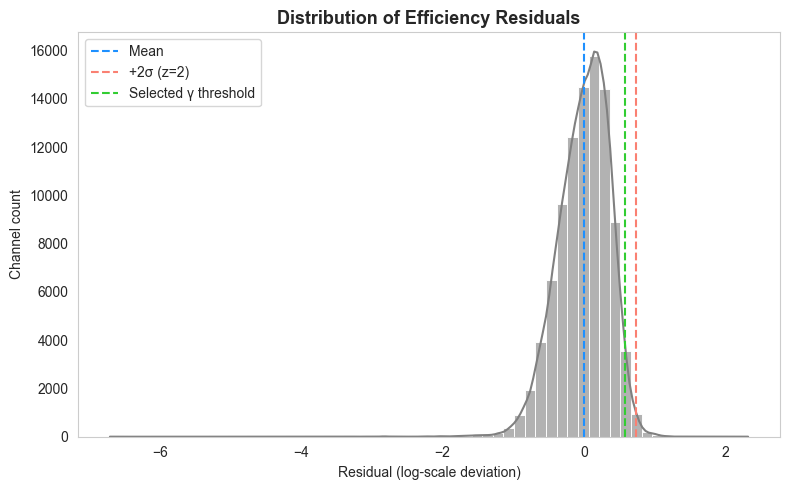

In [31]:
gamma = np.percentile(channels_model["residual"], 97)
plot_residual_distribution(channels_model["residual"], threshold_gamma=gamma)

In [42]:
is_outperformer_mask = channels_model["residual"] > gamma
channel_df["is_outperformer"] = is_outperformer_mask.reindex(channel_df.index, fill_value=False)

In [44]:
outperformers_df = channel_df[channel_df['is_outperformer']]
non_outperformers_df = channel_df[~channel_df['is_outperformer']]
print(len(outperformers_df))
outperformers_df.head(6)

2831


,category_cc,join_date,channel,name_cc,subscribers_cc,videos_cc,subscriber_rank_sb,weights,channel_age_days,videos_per_day,avg_engagement_efficiency,total_views,total_duration,total_like_count,total_dislike_count,total_num_comms,avg_video_like_ratio,video_count_processed,is_outperformer
27568,Music,2012-06-17,UCGnEWsLelLFqMkWcb8s7-nA,孤独なghost,93200,121,88557.0,3.9875,2688.0,0.045015,0.105720,9817455.0,25500.0,845110.0,3881.0,10345.0,0.996371,125,True
29460,People & Blogs,2016-11-05,UCwpAYjmPdYVw6ZNoiul8g2Q,Muhammad Arbaz Offic...,84050,175,95847.0,3.7155,1086.0,0.161142,0.161395,4066492.0,68508.0,303546.0,20696.0,65870.0,0.968095,181,True
30591,Gaming,2019-01-16,UCrDEwtROpcijOFP9uMwz19Q,Parallel Samzyy,79100,40,99714.0,3.7395,284.0,0.140845,0.098866,6788720.0,9521.0,604033.0,11725.0,10072.0,0.979401,51,True
32883,Pets & Animals,2015-12-16,UCkrkMMAyxC9vGNa6ZJYyscg,Takis Shelter - The ...,73600,316,109765.0,5.0415,1411.0,0.223955,0.151517,22679099.0,91716.0,1207584.0,9496.0,104127.0,0.995255,340,True
32943,Gaming,2011-09-27,UC3-8qZ-rZvlSVWwkHoeelCA,TheMythicalSausage,83000,1766,110160.0,5.0940,2952.0,0.598238,0.094543,12100847.0,3513327.0,416318.0,7942.0,87631.0,0.977471,1773,True
33055,Gaming,2019-04-17,UCaH2302aYnmOJH-CWn-Bebg,Military Dave,84100,52,110730.0,4.9860,193.0,0.269430,0.110061,2810462.0,21462.0,304313.0,17771.0,30004.0,0.864303,55,True


#### III. Categories of quiet outperformers

Initially, dataset provides us a correspondence of each channel to 1 of 15 predefined categories. Let's see, how quiet outperformers are distributed by those categories and how they relate to overall distribution of categories among all channels.

_Note: those categories can be then upgraded by using some additional metadata about videos, such as tags or description data. We explore this on Research Question 2._

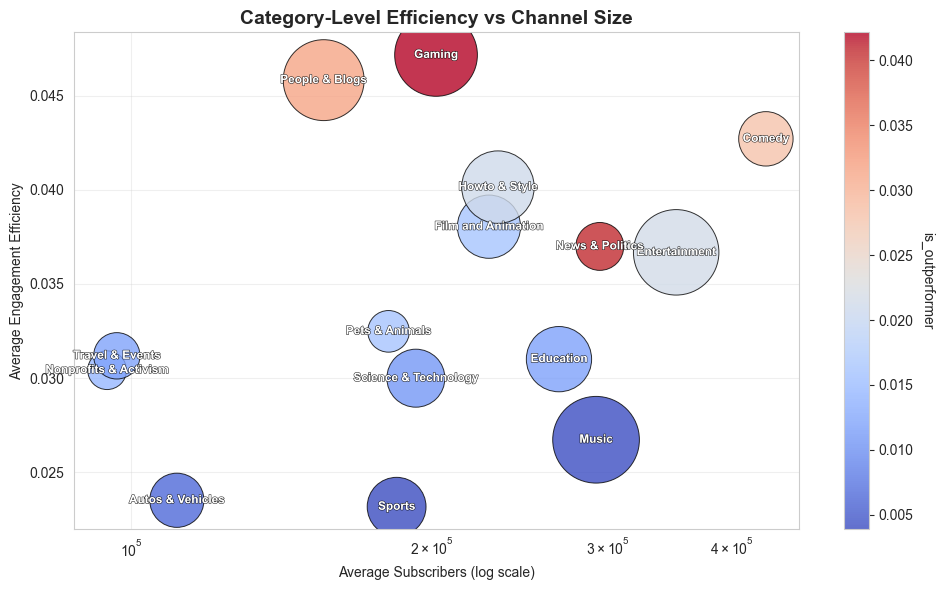

In [45]:
plot_category_bubble(
    dataframe=channel_df,
    size_column="subscribers_cc",
    value_column="avg_engagement_efficiency",
    category_column="category_cc",
    color_column="is_outperformer",  # average will give share of outperformers
    plot_title="Category-Level Efficiency vs Channel Size",
    x_axis_label="Average Subscribers (log scale)",
    y_axis_label="Average Engagement Efficiency",
)

#### IV. Diving into one Outperformer

Let’s take a closer look at one of the top quiet outperformers, the channel “Gym Monk / Gaming.”
This channel still exists today with around 28K subscribers, and during the 2019 period it had multiple videos reaching hundreds of thousands of views.

In [86]:
# Loading the time series data
timeseries_df = pd.read_parquet(DATASET_TIMESERIES)

In [17]:
channel = 'UCfs20O_RuLJXGGTxv5VIzdw'
channel_timeseries = timeseries_df[timeseries_df['channel'] == channel]
channel_timeseries.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
12899150,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-04-25,26360.750,63.750,1775.750,0.000,77,0,11,2016-04-19,1.208036,1.208036
12899151,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-02,26807.000,446.250,1795.000,19.250,77,0,6,2016-04-26,NaN,NaN
12899152,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-09,27071.250,264.250,1806.375,11.375,78,1,1,2016-05-03,1.193830,1.193830
12899153,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-16,27407.500,336.250,1814.750,8.375,80,2,3,2016-05-10,1.154780,1.154780
12899154,UCfs20O_RuLJXGGTxv5VIzdw,Gaming,2016-05-23,28045.125,637.625,1830.125,15.375,84,4,6,2016-05-17,0.880374,0.880374


Let's compare his efficiency(outperformer) to someone who is in the same category "Gaming" and has an average efficiency.


In [31]:
target_channel = "UCfs20O_RuLJXGGTxv5VIzdw"
target_eff = channel_df.loc[channel_df["channel"] == target_channel, "avg_engagement_efficiency"].iloc[0]

# Find average efficiency for Gaming category
avg_eff_gaming = (
    channel_df.loc[channel_df["category_cc"] == "Gaming", "avg_engagement_efficiency"]
    .mean()
)

# Find channel in Gaming closest to that average
avg_channel = (
    channel_df[channel_df["category_cc"] == "Gaming"]
    .assign(diff=lambda x: (x["avg_engagement_efficiency"] - avg_eff_gaming).abs())
    .sort_values("diff")
    .iloc[0]
)

avg_channel_id = avg_channel["channel"]
avg_channel_eff = avg_channel["avg_engagement_efficiency"]

print(f"Matched 'average' Gaming channel: {avg_channel_id}")

Matched 'average' Gaming channel: UCRZ5-H-PV_2jsj3JsB9uU2A


In [34]:
channel_2 = 'UCRZ5-H-PV_2jsj3JsB9uU2A'
channel_timeseries_2 = timeseries_df[timeseries_df['channel'] == channel_2]
channel_timeseries_2.head(5)

,channel,category,datetime,views,delta_views,subs,delta_subs,videos,delta_videos,activity,week_start,efficiency_4week,efficiency_4week_filled
8395116,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-02,178813.500,751.500,831.000,0.000,5,0,0,2016-04-26,NaN,NaN
8395117,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-09,180609.500,1796.000,837.750,6.750,5,0,0,2016-05-03,NaN,NaN
8395118,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-16,182562.375,1952.875,845.125,7.375,6,1,1,2016-05-10,0.012577,0.012577
8395119,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-23,184819.000,2256.625,860.000,14.875,7,1,2,2016-05-17,0.010054,0.010054
8395120,UCRZ5-H-PV_2jsj3JsB9uU2A,Gaming,2016-05-30,186508.625,1689.625,867.000,7.000,8,1,2,2016-05-24,0.015791,0.015791


H₀ (null hypothesis):
The outperformer’s engagement efficiency over time is not significantly different from that of an average Gaming channel.

H₁ (alternative hypothesis):
The outperformer’s engagement efficiency is significantly higher than that of an average Gaming channel.

In [42]:
target_ts = timeseries_df.loc[timeseries_df["channel"] == target_channel].copy()
avg_ts = timeseries_df.loc[timeseries_df["channel"] == avg_channel].copy()

# Drop missing values
eff_out = target_ts["efficiency_4week_filled"].dropna()
eff_avg = avg_ts["efficiency_4week_filled"].dropna()

# Mann-Whitney U test (one-sided: outperformer > average)
stat, p_value = mannwhitneyu(eff_out, eff_avg, alternative="greater")

print(f"Mann–Whitney U statistic: {stat:.3f}")
print(f"p-value: {p_value:.6f}")

Mann–Whitney U statistic: 7840.000
p-value: 0.000000


To assess whether the outperformer’s engagement efficiency is statistically higher than that of a typical Gaming channel, we performed a one-sided Mann–Whitney U test on their weekly efficiency distributions.
The test yielded a U statistic of 7840 and a p-value < 0.000001, allowing us to reject the null hypothesis of equal engagement levels.
This confirms that the outperformer’s audience interacts significantly more per view than viewers of a comparable average Gaming channel.

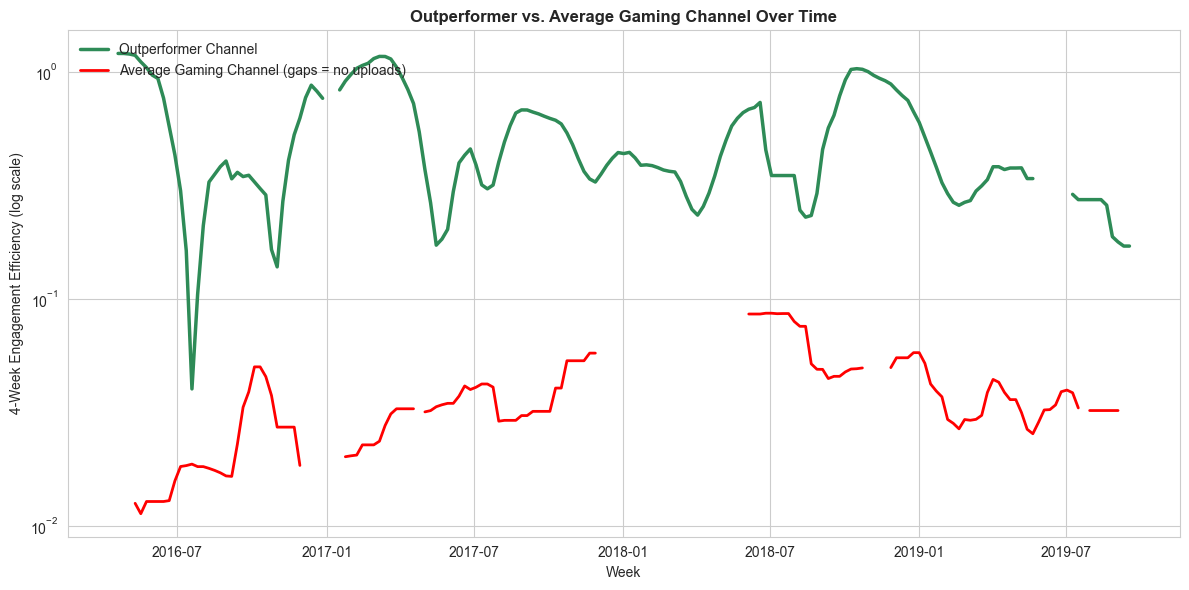

In [40]:
plot_channel_comparison(
    df=timeseries_df,
    target_channel=target_channel,
    avg_channel_id=avg_channel_id,
)

As expected, the outperformer channel achieves consistently higher engagement efficiency than the average Gaming channel throughout the observed period.
Additionally, the outperformer shows fewer and shorter inactivity gaps, indicating a more consistent upload pattern and sustained audience engagement over time.


These observations motivate our subsequent research questions. Having established that a quiet outperformer achieves consistently higher engagement efficiency and more stable activity than a comparable average Gaming channel, we next ask whether this pattern generalizes across the platform. Specifically, we investigate how quiet outperformers are distributed across content communities (RQ2), which structural or strategic choices, such as posting frequency, duration, or timing, are statistically associated with higher efficiency within each size tier and content type (RQ3), and finally, whether quiet outperformers sustain more stable growth in views and subscribers compared to similar non-outperforming channels (RQ4). Together, these questions aim to uncover the structural and behavioral factors that differentiate quiet outperformers from typical creators beyond raw engagement metrics.

## 5. Mathematical model of Research Questions

This section presents the detailed methods proposed for each research question.

### RQ2: Are quiet outperformers concentrated in particular content categories, or do their engagement efficiency patterns vary across categories?

---

#### 1. Choice of Content Categorization

We consider two approaches to define a channel's content category: (a) Using YouTube's 15 official categories, (b) Using data-driven clusters
To better capture real content communities, we construct data-driven clusters from video-level textual data (tags).

This approach is feasible in our setting with the new lightweight dataset (tags_processed.parquet) containing only channel_id, display_id, tags, and upload_date (reducing the original metadata file from 13 GB to 5 GB). Also instead of loading the entire dataset at once, we can iterate through it in manageable chunks using the iterate_parquet_stream function we built in the data loader.

#### 2. Building Data-Driven Content Clusters

##### 2.1 Text Preprocessing
For each video:
1. Clean tags text:
   - lowercase
   - remove punctuation, stopwords, and numbers
   - lemmatize or stem words
2. Join all tags into one document string per video.


##### 2.2 Text Representation
We represent each video's tags as a mixture of latent topics using **Latent Dirichlet Allocation (LDA)**, a probabilistic topic modeling approach.

We considered to use transformer embeddings (e.g., Sentence-BERT) and density-based clustering (HDBSCAN), which captures semantic similarity more effectively than LDA but is computationally expensive for millions of short tag strings and sensitive to parameter tuning. So we decided to use LDA.


LDA assumes that:
- each video's tag set is generated from a mixture of *K* latent topics, and
- each topic is a probability distribution over words.

Formally, for each video *v* (treated as a “document” of tags):

$$
\theta_v \sim \text{Dirichlet}(\alpha), \quad \phi_k \sim \text{Dirichlet}(\beta)
$$

where
- $\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK})$ represents the topic proportions for video *v*,
- $\phi_k$ is the word distribution for topic *k*,
- $\alpha$ and $\beta$ are Dirichlet hyperparameters controlling sparsity.

Each tag $w_{vn}$ in video *v* is generated by:
$$
z_{vn} \sim \text{Multinomial}(\theta_v), \quad w_{vn} \sim \text{Multinomial}(\phi_{z_{vn}})
$$

After fitting the model, each video is represented by its topic distribution vector:

$$
\theta_v = (\theta_{v1}, \theta_{v2}, ..., \theta_{vK}), \quad \sum_{k=1}^{K} \theta_{vk} = 1
$$

We determine the optimal number of topics *K* using **topic coherence** and **perplexity** metrics.
- Higher coherence indicates more interpretable and distinct topics.
- Lower perplexity indicates better generalization to unseen data.

Each topic is then characterized by its most probable words, and then summarized using a large language model (LLM) for interpretability.

Once trained, we assign each video to its dominant topic:
$$
\text{Topic}(v) = \arg\max_k \theta_{vk}
$$

These inferred topics form data-driven content categories, which are later aggregated to the channel level (next step).

#### 3. Aggregating Clusters to the Channel Level

Because quiet outperformers are defined at the channel level, we aggregate the video clusters as follows:

1. Count the number of videos per cluster for each channel:

    $$
    n_{c,k} = \mathrm{\#\ of\ videos\ from\ channel\ } c \mathrm{\ in\ cluster\ } k
    $$

2. Compute each channel's cluster proportion:

    $$
    p_{c,k} = \frac{n_{c,k}}{\sum_{j} n_{c,j}}
    $$

3. Assign the dominant cluster:

    $$
    \text{Cluster}_c = \arg\max_k p_{c,k}
    $$

4. Compute topic diversity using Shannon entropy:

    $$
    H_c = -\sum_k p_{c,k} \log(p_{c,k})
    $$

    Channels with high entropy (e.g., $H_c > 1.5$) can be excluded to focus on thematically consistent creators.

#### 4. Comparing Engagement Efficiency Among Quiet Outperformers Across Categories

Let $\hat{\varepsilon}_c$ denote the *residual efficiency* for channel $c$, derived from RQ1, and let $k$ denote its assigned content category or cluster (from YouTube's predefined categories or LDA-derived topics).

##### 4.1 Summary Statistics and Visualization

For each category $k$, compute descriptive statistics among quiet outperformers:
$$
\text{Mean}_k = \frac{1}{n_k} \sum_{c \in k} \hat{\varepsilon}_c, \quad
\text{Median}_k, \quad \text{IQR}_k, \quad \text{SD}_k
$$

Visualize the efficiency distributions across categories using violin plots, boxplots**, or kernel density plots (KDE).
These visuals reveal whether outperformers from certain content types (e.g., Education, Gaming, Lifestyle) tend to achieve systematically higher engagement efficiency.

##### 4.2 Testing Differences in Efficiency Distributions

To formally test whether efficiency distributions differ across categories, apply the Kruskal-Wallis H test:

$$
H_0: f_1(\hat{\varepsilon}) = f_2(\hat{\varepsilon}) = \dots = f_K(\hat{\varepsilon})
$$

$$
H = \frac{12}{N(N+1)} \sum_{k=1}^{K} n_k (\bar{R}_k - \bar{R})^2
$$

where:
- $n_k$ = number of outperformers in category $k$
- $\bar{R}_k$ = mean rank of efficiency in category $k$
- $\bar{R}$ = mean rank overall
- $N$ = total number of outperformers

If $p < 0.05$, we reject $H_0$ and conclude that at least one content category of outperformers exhibits a distinct engagement efficiency distribution.

If the global test is significant, perform Dunn's post-hoc tests with False Discovery Rate correction to identify which categories differ.


##### 4.3 Concentration of Outperformers Across Categories

To assess whether quiet outperformers are disproportionately represented in certain content types, compare the observed vs. expected counts of outperformers per category using a **Chi-square goodness-of-fit test**:

$$
\chi^2 = \sum_{k=1}^{K} \frac{(O_k - E_k)^2}{E_k}
$$

where:
- $O_k$ = observed number of outperformers in category $k$
- $E_k$ = expected number based on overall category proportions in the full dataset

A significant result ($p < 0.05$) indicates that outperformers are concentrated in specific content categories rather than evenly distributed.



### RQ3: Which structural choices (video duration, posting frequency, posting consistency) are statistically associated with higher efficiency within each size tier?

---




We analyze how structural choices relate to engagement efficiency while removing scale effects and comparing channels within size tiers. Because efficiency co-varies with subscriber count and channels differ by composition, naive comparisons are biased. We address this by (i) residualizing efficiency against size in a log–log baseline, and (ii) estimating within-tier regressions.

#### 1. Outcome Metric: Size-Adjusted Efficiency (Residual)

From the channel efficiency we computed before,

Baseline (size) model:
$$
\log_{10}(E_c) \;=\; a + b\,\log_{10}(\text{subscribers}_c) + \varepsilon_c.
$$

Residual (outcome):
$$
r_c \;=\; \log_{10}(E_c) - \big(a + b\,\log_{10}(\text{subscribers}_c)\big).
$$
Here, $r_c>0$ indicates performance above size-based expectation.

#### 2. Size Tiers

Tiers are defined by subscriber quantiles:
- Small: 0–50th percentile
- Mid: 50–90th percentile

Analyses are run separately within each tier.


#### 3. Structural Predictors (8-week window)

All predictors are backward-looking (no leakage) and summarized at the channel level:

- Posting frequency (pace): median weekly uploads over the prior 8 weeks.
- Posting consistency (0–1):
$$
\text{cons8} \;=\; \mathrm{clip}\!\left(1-\frac{\mathrm{std}_8}{\max(\mathrm{mean}_8,\varepsilon)},\,0,\,1\right),\quad \varepsilon=0.1.
$$
- Video duration: channel median duration; modeled as $\log(\text{duration})$ to reduce skew.

Predictors are z-scored within tier to make coefficients comparable.

#### 4. Estimation and Final Tests

Within each tier, we estimate a **weighted least squares** regression:
$$
r_c \;=\; \beta_0 + \beta_1\,\text{pace8}_c + \beta_2\,\text{cons8}_c + \beta_3\,\log(\text{duration}_c) \, + \, \text{controls (category FE, log age, videos/day, ... )} \, + \, \varepsilon_c.
$$

- Weights: number of videos for the channel (precision weighting of $r_c$).
- Standard errors: HC3 (heteroskedasticity-robust with a leverage adjustment).
- Final tests: two-sided tests of $H_0:\beta_k=0$ for pace, consistency, and duration in each tier.
- Effect sizes: report predicted change in $r_c$ from 25th→75th percentile for each factor with 95% CIs; translate to % on the original scale for readability.

#### 5. Robustness

- Recompute predictors with 4w and 12w windows.
- Duration variants: trimmed mean
- Check pace–consistency collinearity; confirm stability.


**Interpretation.** A positive and significant $\beta_2$ indicates that more consistent posting is associated with higher size-adjusted efficiency within that tier; $\beta_1$ captures frequency beyond consistency; $\beta_3$ summarizes how typical (log) duration relates to efficiency after basic controls.


### RQ4:Do quiet outperformers exhibit more stable and consistent growth in weekly views and subscribers compared to non-outperforming channels with similar characteristics?

---

To answer this question, we compare the long-term growth volatility of two groups: "Outperformers" (treated) and "non-Outperformers" (control). Unlike event-based analyses where treatment occurs at a specific time, our treatment is status-based: channels are classified as outperformers according to their engagement efficiency. Because outperformers are not randomly assigned and tend to differ in characteristics such as size, age, and category, a simple comparison would be biased. This selection bias introduces confounding, which we address using a quasi-causal inference framework based on Propensity Score Matching (PSM).

Due to the complexity of this analysis, it is divided into two Jupyter notebooks that are in the `src/notebooks` folder, that can be consulted for full details. In the next milestone, we will present the complete results and findings.

The notebooks are located here:
- `src/notebooks/sustainability_test_channel.ipynb`
- `src/notebooks/sustainability_outperformers_vs_control.ipynb`


#### 1. Outcome Metric: Growth Volatility (Coefficient of Variation)

To quantify growth stability, we first define growth volatility as the **Coefficient of Variation (CV)**. This metric is calculated over a 12-month (52-week) window for each channel's weekly change in views ($\Delta \text{Views}$) and subscribers ($\Delta \text{Subs}$). This specific subset was chosen for computational feasibility and practical relevance, allowing for robust conclusions to be drawn from the most recent yearly data. This confirmed that the data size was manageable and allowed us to isolate a high-quality subset for analysis.

The CV is the ratio of the standard deviation ($\sigma$) to the mean ($\mu$) of this weekly growth:

$$
\text{CV} = \frac{\sigma_{\text{growth}}}{\mu_{\text{growth}}}
$$

The CV is a crucial metric for this analysis because it is scale-independent. It normalizes volatility relative to the channel's average growth, allowing for a fair comparison between channels of vastly different sizes (e.g., a channel with 10k subscribers vs. one with 10M). A lower CV indicates lower volatility and thus higher sustainability.


#### 2. Causal Methodology: Propensity Score Matching (PSM)

We use **Propensity Score Matching (PSM)** to create a synthetic control group that is statistically similar to the treated group across all observed covariates ($X$). This allows us to estimate the causal effect of being an Outperformer on growth volatility, isolating it from confounding factors like channel size or age.

The methodology relies on the propensity score, $e(X)$, which is the conditional probability of a channel being in the treated group (Outperformer) given its pre-treatment covariates $X$:

$$
e(X) = P(\text{is\_outperformer} = 1 \mid X)
$$

#### 3. Propensity Score Model

We estimate the propensity score $e(X)$ using a **Logistic Regression** model.

##### 3.1 Model Covariates and Transformations
The model predicts the treatment (`is_outperformer`) based on a set of key confounding variables:

$$
\text{logit}(e(X)) = \beta_0 + \beta_1 \cdot \log(\text{channel\_age\_days}) + \beta_2 \cdot \log(\text{videos\_cc}) + \dots
$$

* **Logarithmic Transformation**: Covariates such as `subscribers_cc`, `channel_age_days`, and `videos_cc` are heavily right-skewed. We apply a $\text{log()}$ transformation to these features. This compresses the scale, mitigates the influence of extreme outliers, and better approximates the linear relationship assumed by the logistic regression's logit link function.

* **Non-Linear Terms**: To improve model fit, we may introduce quadratic terms (e.g., \( I([\log(\text{subscribers\_cc})]^2) \)). This allows the model to capture non-linear relationships.


* **Regularization**: To stabilize the model coefficients against outliers and prevent overfitting, we apply $\mathbf{L2\ regularization}$ (Ridge regression) during the model fitting process.

#### 4. Matching Process and Balance Check

After estimating propensity scores for all channels, we perform 1:1 nearest-neighbor matching to create a balanced dataset.

* **Exact Matching**: We enforce exact matching on the `category_cc` variable. This ensures that a treated "Gaming" channel is only ever matched with a control "Gaming" channel, eliminating bias from content category differences.

* **Caliper Matching**: We impose an extremely tight caliper (e.g., $0.0005$). This means a match is only considered valid if the absolute difference in propensity scores between the treated and control unit is less than this caliper value, ensuring only highly similar channels are paired.

##### Standardized Mean Difference (SMD)
To verify the success of the matching process, we assess covariate balance using the Standardized Mean Difference (SMD). The SMD measures the difference in means between the treated and control groups in units of pooled standard deviation:

$$
\text{SMD} = \frac{\bar{X}_{\text{Treated}} - \bar{X}_{\text{Control}}}{\sqrt{\frac{S_{\text{Treated}}^2 + S_{\text{Control}}^2}{2}}}
$$

SMD is a critical diagnostic. Before matching, a large SMD ($|\text{SMD}| > 0.1$) indicates imbalance and justifies the need for matching. After matching, we require $|\text{SMD}| < 0.1$ for all covariates to confirm that the groups are statistically comparable and selection bias has been minimized.


#### 5. Final Statistical Test

The final step is to compare the outcome (CV) between the newly balanced treated and control groups.

* **Mann-Whitney U Test**: Visual inspection (histograms, Q-Q plots) and formal tests (e.g., Shapiro-Wilk) confirm that the CV metrics are not normally distributed. Therefore, we use the Mann-Whitney U test, a non-parametric equivalent of the t-test. This test ranks the data and compares the median of the two groups, allowing us to reliably test the hypothesis that Outperformers and Control channels have different median growth volatility without violating distributional assumptions.